# Lecture 12: Feature importances and model interpretation

This demo is based on the [Lecture 12 notes](https://ubc-cs.github.io/cpsc330-book/book/12_feat-importances.html).
How does a fitted model use its inputs, and what contributed to one prediction?

Our workflow: review housing preprocessing → inspect correlations → interpret ridge coefficients → compare tree and permutation importances → explain individual predictions with SHAP.

By the end, you should be able to interpret coefficients in the correct units, distinguish global importance from local explanations, and explain why model behaviour does not establish causation.

## Setup and imports

Run this notebook from `content/classes/varada` using this directory's `.venv` kernel. Place the labelled housing CSV at `data/housing-kaggle/train.csv` and the Adult CSV at `data/adult.csv`. Run cells in order.

The demo uses LightGBM and SHAP. If needed, install them before class with `uv pip install --python .venv/bin/python lightgbm shap`.

We use the chapter's preprocessing and fixed model settings. Adult explanations use validation data; test sets stay reserved.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from lightgbm import LGBMClassifier
import shap

%matplotlib inline
DATA_DIR = Path("data")
plt.rcParams.update({"figure.figsize": (8, 4)})

for relative_path in ["housing-kaggle/train.csv", "adult.csv"]:
    data_path = DATA_DIR / relative_path
    if not data_path.is_file():
        raise FileNotFoundError(f"Place the dataset at {data_path.resolve()} and run from content/classes/varada.")

Matplotlib is building the font cache; this may take a moment.


## 1. Load housing data and review preprocessing

Predict `SalePrice` in dollars and reserve 10% for testing. We reuse Chapter 10's decisions:

| Features | Transformation |
|---|---|
| Numeric measurements | Median imputation with missing indicators, then scaling |
| Quality ratings and `Functional` | Impute, ordinal encode in explicit order, then scale |
| Other categorical columns | Fill unknowns with `Unknown`, then one-hot encode |
| `Id` | Drop |

Preserve the literal category `None` when reading the CSV. Use recorded measurements to distinguish absent amenities from unknown ratings. Amenity absence is categorical; it is not another step on the quality scale. These fixed rules do not learn from the data. Imputation and scaling remain inside model pipelines.

In [2]:
df = pd.read_csv(
    DATA_DIR / "housing-kaggle/train.csv",
    keep_default_na=False,
    na_values=["", "NA"],
)
train_df, test_df = train_test_split(df, test_size=0.10, random_state=123)


X_train = train_df.drop(columns=["SalePrice"])
y_train = train_df["SalePrice"]

X_test = test_df.drop(columns=["SalePrice"])
y_test = test_df["SalePrice"]



def mark_absent_amenities(X):
    X = X.copy()
    amenity_columns = {
        "TotalBsmtSF": ["BsmtQual", "BsmtCond", "BsmtExposure",
                        "BsmtFinType1", "BsmtFinType2"],
        "Fireplaces": ["FireplaceQu"],
        "GarageArea": ["GarageType", "GarageFinish", "GarageQual", "GarageCond"],
        "PoolArea": ["PoolQC"],
    }
    for measurement, columns in amenity_columns.items():
        absent = X[measurement].eq(0)
        X.loc[absent, columns] = X.loc[absent, columns].fillna("Absent")

    for column in ["Alley", "Fence", "MiscFeature"]:
        X[column] = X[column].fillna("Absent")
    return X


X_train = mark_absent_amenities(X_train)
X_test = mark_absent_amenities(X_test)


drop_features = ["Id"]
numeric_features = [
    "BedroomAbvGr",
    "KitchenAbvGr",
    "LotFrontage",
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "BsmtFullBath",
    "BsmtHalfBath",
    "FullBath",
    "HalfBath",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageYrBlt",
    "GarageCars",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
    "YrSold",
]

ordinal_features_reg = ["ExterQual", "ExterCond", "HeatingQC", "KitchenQual"]
ordering = ["Po", "Fa", "TA", "Gd", "Ex"]
ordering_ordinal_reg = [ordering] * len(ordinal_features_reg)

ordinal_features_oth = ["Functional"]
ordering_ordinal_oth = [
    ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
]

assigned_features = (
    drop_features + numeric_features + ordinal_features_reg + ordinal_features_oth
)
categorical_features = [
    column for column in X_train.columns if column not in assigned_features
]

numeric_transformer = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
)
ordinal_transformer_reg = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_reg),
    StandardScaler(),
)
ordinal_transformer_oth = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_oth),
    StandardScaler(),
)
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="Unknown"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessor = make_column_transformer(
    ("drop", drop_features),
    (numeric_transformer, numeric_features),
    (ordinal_transformer_reg, ordinal_features_reg),
    (ordinal_transformer_oth, ordinal_features_oth),
    (categorical_transformer, categorical_features),
    verbose_feature_names_out=False,
)

## 2. Correlation describes the data

**Predict:** Will larger houses tend to have higher prices? Does that tell us which area measurement a model will use?

Pearson correlation measures linear association between pairs of columns. A value near zero can hide a non-linear relationship. The following uses training data only.

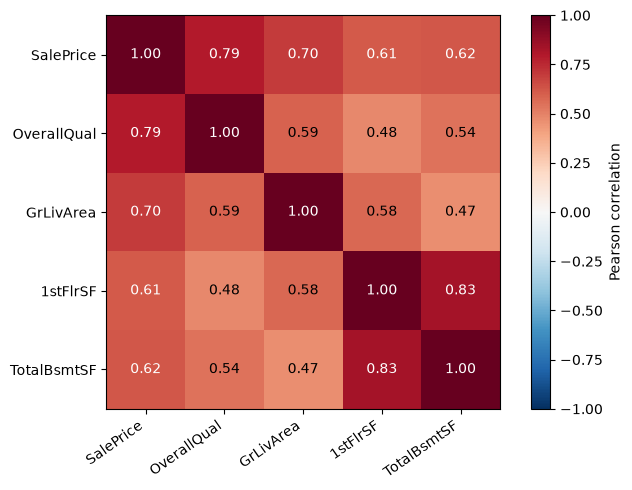

In [3]:
corr_columns = ["SalePrice", "OverallQual", "GrLivArea", "1stFlrSF", "TotalBsmtSF"]
corr = train_df[corr_columns].corr()
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for row in range(len(corr)):
    for col in range(len(corr)):
        ax.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[row, col]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

**Discuss:** Compare `GrLivArea`–`SalePrice` with `1stFlrSF`–`TotalBsmtSF`. How could related measurements complicate an importance ranking?

Correlation describes associations in the data. Coefficients describe a fitted prediction rule. Neither establishes a causal effect.

## 3. Interpret ridge coefficients

First compare ridge with a training-mean baseline using five-fold cross-validation. Each fold learns its own preprocessing.

In [4]:
house_pipe = make_pipeline(clone(preprocessor), Ridge(alpha=100))
house_scores = {}
for name, estimator in {
    "Predict training mean": DummyRegressor(),
    "Ridge": house_pipe,
}.items():
    scores = cross_validate(estimator, X_train, y_train, cv=5, scoring="r2")
    house_scores[name] = {
        "Mean validation R2": scores["test_score"].mean(),
        "SD across folds": scores["test_score"].std(),
    }
pd.DataFrame(house_scores).T

,Mean validation R2,SD across folds
Predict training mean,-0.005307,0.005636
Ridge,0.797221,0.097971


In [5]:
house_pipe.fit(X_train, y_train)
house_preprocessor = house_pipe.named_steps["columntransformer"]
house_coefs = pd.Series(
    house_pipe.named_steps["ridge"].coef_,
    index=house_preprocessor.get_feature_names_out(),
    name="Coefficient",
)
house_coefs.reindex(house_coefs.abs().sort_values(ascending=False).index).head(10)

OverallQual             14071.079678
GrLivArea               11501.817023
BsmtQual_Ex             11170.908367
Neighborhood_NoRidge     9373.965731
Neighborhood_NridgHt     8397.405152
GarageCars               8262.693270
2ndFlrSF                 8075.399323
BsmtExposure_Gd          7305.454377
Condition1_Norm          7145.332642
1stFlrSF                 6681.399715
Name: Coefficient, dtype: float64

### Numeric features: account for scaling

A coefficient is the change in predicted dollars per unit of the **transformed input**, holding other transformed inputs fixed. For a standardized measurement, one unit is one fitted training standard deviation.

Retrieve the scale from this model's own fitted preprocessor. Missing indicators also receive coefficients, so use the imputer's feature names when matching scales.

In [6]:
numeric_branch = house_preprocessor.named_transformers_["pipeline-1"]
numeric_names = numeric_branch.named_steps["simpleimputer"].get_feature_names_out(numeric_features)
numeric_scales = pd.Series(
    numeric_branch.named_steps["standardscaler"].scale_, index=numeric_names
)
area_scale = numeric_scales["LotArea"]
area_coef = house_coefs["LotArea"]
pd.Series({
    "Training scale in square feet": area_scale,
    "Dollars per scaled unit": area_coef,
    "Dollars per additional square foot": area_coef / area_scale,
})

Training scale in square feet         8994.471032
Dollars per scaled unit               3421.864806
Dollars per additional square foot       0.380441
dtype: float64

**Predict:** How much will the prediction change if we add 1,000 square feet to an observed `LotArea`?

Expected change = coefficient × 1,000 / fitted scale. We edit an observed value so its missing indicator stays unchanged.

In [7]:
house = X_train.loc[X_train["LotArea"].notna()].iloc[[0]].copy()
larger_lot = house.copy()
larger_lot["LotArea"] += 1000
area_expected = area_coef * 1000 / area_scale
area_actual = (house_pipe.predict(larger_lot) - house_pipe.predict(house))[0]
np.testing.assert_allclose(area_actual, area_expected)
pd.Series({"Change from coefficient ($)": area_expected,
           "Change from predictions ($)": area_actual})

Change from coefficient ($)    380.440917
Change from predictions ($)    380.440917
dtype: float64

### Ordinal features: encoding and scaling both matter

`ExterQual` uses `Po < Fa < TA < Gd < Ex`, followed by scaling. A one-category increase changes its encoded value by one, so divide its fitted coefficient by the ordinal scaler's scale.

**Predict:** Would the coefficient alone give the change from `Gd` to `Ex`?

In [8]:
ordinal_scale = pd.Series(
    house_preprocessor.named_transformers_["pipeline-2"].named_steps["standardscaler"].scale_,
    index=ordinal_features_reg,
)
good_house = X_train.loc[X_train["ExterQual"].eq("Gd")].iloc[[0]].copy()
excellent_house = good_house.copy()
excellent_house["ExterQual"] = "Ex"
quality_expected = house_coefs["ExterQual"] / ordinal_scale["ExterQual"]
quality_actual = (house_pipe.predict(excellent_house) - house_pipe.predict(good_house))[0]
np.testing.assert_allclose(quality_actual, quality_expected)
pd.Series({"Change from coefficient ($)": quality_expected,
           "Change from predictions ($)": quality_actual})

Change from coefficient ($)    9700.424021
Change from predictions ($)    9700.424021
dtype: float64

### Categorical features: compare two coefficients

All one-hot categories are retained. Switching from gentle to moderate slope removes one indicator and adds another. The predicted change is therefore the moderate coefficient minus the gentle coefficient.

In [9]:
slope_coefs = house_coefs[house_coefs.index.str.startswith("LandSlope_")]
pd.DataFrame({
    "Coefficient": slope_coefs,
    "Difference from Gentle ($)": slope_coefs - slope_coefs["LandSlope_Gtl"],
})

,Coefficient,Difference from Gentle ($)
LandSlope_Gtl,-2365.345172,0.000000
LandSlope_Mod,3174.619024,5539.964196
LandSlope_Sev,-809.273853,1556.071319


In [10]:
gentle_house = X_train.loc[X_train["LandSlope"].eq("Gtl")].iloc[[0]].copy()
moderate_house = gentle_house.copy()
moderate_house["LandSlope"] = "Mod"
slope_expected = slope_coefs["LandSlope_Mod"] - slope_coefs["LandSlope_Gtl"]
slope_actual = (house_pipe.predict(moderate_house) - house_pipe.predict(gentle_house))[0]
np.testing.assert_allclose(slope_actual, slope_expected)
pd.Series({"Change from coefficients ($)": slope_expected,
           "Change from predictions ($)": slope_actual})

Change from coefficients ($)    5539.964196
Change from predictions ($)     5539.964196
dtype: float64

**Discuss:** Do these prediction checks tell us what a renovation would do to a house's sale price?

They verify the fitted model's arithmetic. Related inputs, encoding, scaling, and regularization affect the coefficients. If the encoder dropped a reference category, the remaining coefficients would describe differences from that category.

## 4. Adult data: fit models for interpretation

We predict whether recorded income exceeds $50,000 in this historical census dataset. Reserve 20% for testing, then make a stratified validation split from the development data. Replace `?` with missing values using a fixed rule.

| Features | Transformation |
|---|---|
| Age, capital gains/losses, hours per week | Standardize |
| Education | Ordinal encode in the dataset's code order |
| Recorded sex | Binary indicator |
| Workclass, marital status, occupation, relationship, native country | Impute and one-hot encode |
| `fnlwgt`, `race`, `education.num` | Drop |

The target is explicitly encoded as 1 for `>50K`. Education's order is a coding convention; a linear model assumes equal effects per step. Dropping race does not establish fairness.

In [11]:
adult = pd.read_csv(DATA_DIR / "adult.csv")
adult_development, adult_test = train_test_split(adult, test_size=0.2, random_state=42)
adult_fit, adult_valid = train_test_split(
    adult_development, test_size=0.25, random_state=123,
    stratify=adult_development["income"],
)
adult_fit = adult_fit.replace("?", np.nan)
adult_valid = adult_valid.replace("?", np.nan)

numeric_features = ["age", "capital.gain", "capital.loss", "hours.per.week"]

categorical_features = [
    "workclass",
    "marital.status",
    "occupation",
    "relationship",
    "native.country",
]

ordinal_features = ["education"]
binary_features = ["sex"]
drop_features = ["fnlwgt", "race", "education.num"]
target_column = "income"
education_levels = [
    "Preschool",
    "1st-4th",
    "5th-6th",
    "7th-8th",
    "9th",
    "10th",
    "11th",
    "12th",
    "HS-grad",
    "Some-college",
    "Assoc-voc",
    "Assoc-acdm",
    "Bachelors",
    "Masters",
    "Prof-school",
    "Doctorate",
]
numeric_transformer = StandardScaler()

ordinal_transformer = OrdinalEncoder(categories=[education_levels], dtype=int)

binary_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(drop="if_binary", dtype=int),
)
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

adult_preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (ordinal_transformer, ordinal_features),
    (binary_transformer, binary_features),
    (categorical_transformer, categorical_features),
    ("drop", drop_features),
    verbose_feature_names_out=False,
)

assert set(adult_fit["income"]) == {"<=50K", ">50K"}
X_adult_fit = adult_fit.drop(columns="income")
X_adult_valid = adult_valid.drop(columns="income")
y_adult_fit = adult_fit["income"].eq(">50K").astype(int)
y_adult_valid = adult_valid["income"].eq(">50K").astype(int)

### Compare a baseline and three familiar models

Each pipeline receives a cloned preprocessor. Fitting one model cannot overwrite another model's transformations. Compare training and validation accuracy; these fixed settings keep the demo manageable.

In [12]:
adult_models = {
    "Logistic regression": make_pipeline(
        clone(adult_preprocessor), LogisticRegression(max_iter=2000)
    ),
    "Random forest": make_pipeline(
        clone(adult_preprocessor),
        RandomForestClassifier(n_estimators=100, random_state=123, n_jobs=1),
    ),
    "LightGBM": make_pipeline(
        clone(adult_preprocessor),
        LGBMClassifier(random_state=123, verbosity=-1, n_jobs=1),
    ),
}
baseline = DummyClassifier(strategy="most_frequent").fit(X_adult_fit, y_adult_fit)
adult_scores = {"Majority class": {
    "Training accuracy": baseline.score(X_adult_fit, y_adult_fit),
    "Validation accuracy": baseline.score(X_adult_valid, y_adult_valid),
}}
for name, pipe in adult_models.items():
    pipe.fit(X_adult_fit, y_adult_fit)
    adult_scores[name] = {
        "Training accuracy": pipe.score(X_adult_fit, y_adult_fit),
        "Validation accuracy": pipe.score(X_adult_valid, y_adult_valid),
    }
pd.DataFrame(adult_scores).T.round(3)

,Training accuracy,Validation accuracy
Majority class,0.758,0.758
Logistic regression,0.855,0.853
Random forest,0.978,0.852
LightGBM,0.889,0.869


### Logistic regression coefficients

Positive coefficients increase the log-odds of `>50K`, holding other transformed inputs fixed. They are not probability increments. Numeric coefficients refer to standardized units; education refers to one unscaled code step.

In [13]:
adult_lr = adult_models["Logistic regression"]
adult_lr_coefs = pd.Series(
    adult_lr.named_steps["logisticregression"].coef_[0],
    index=adult_lr.named_steps["columntransformer"].get_feature_names_out(),
    name="Log-odds coefficient",
)
adult_lr_coefs.reindex(adult_lr_coefs.abs().sort_values(ascending=False).index).head(8)

capital.gain                        2.305364
marital.status_Married-AF-spouse    1.876896
occupation_Priv-house-serv         -1.540356
marital.status_Never-married       -1.426234
relationship_Own-child             -1.333088
native.country_Columbia            -1.174423
native.country_Greece              -1.090200
relationship_Wife                   1.006413
Name: Log-odds coefficient, dtype: float64

## 5. Global feature importance

### Impurity-based importance

A forest aggregates the reduction in training impurity attributed to its splits. These nonnegative values sum to one; they do not indicate whether a feature pushes a prediction up or down.

**Predict:** Can a feature with many possible split points receive a large importance even if it generalizes poorly?

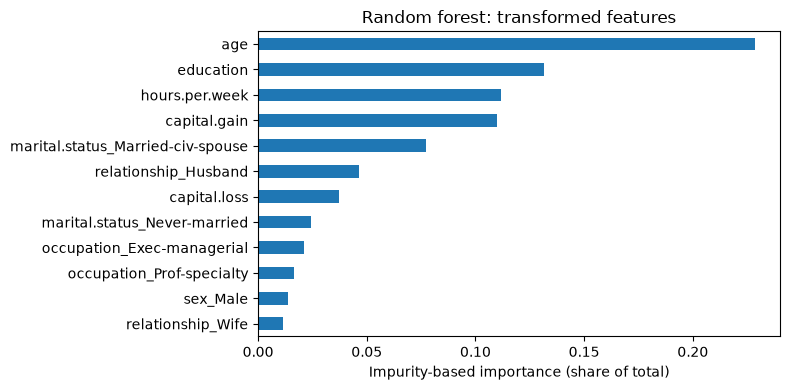

In [14]:
forest_pipe = adult_models["Random forest"]
forest_names = forest_pipe.named_steps["columntransformer"].get_feature_names_out()
impurity_importance = pd.Series(
    forest_pipe.named_steps["randomforestclassifier"].feature_importances_,
    index=forest_names,
).sort_values()
impurity_importance.tail(12).plot.barh()
plt.xlabel("Impurity-based importance (share of total)")
plt.title("Random forest: transformed features")
plt.tight_layout()
plt.show()

### Permutation importance on validation data

Shuffle one original column, predict with the complete fitted pipeline, and measure the decrease in validation accuracy. Repeat without refitting the model. Shuffling before encoding preserves valid one-hot groups.

We use a reproducible subset to keep repeated scoring manageable. A decrease of 0.02 means two percentage points of accuracy.

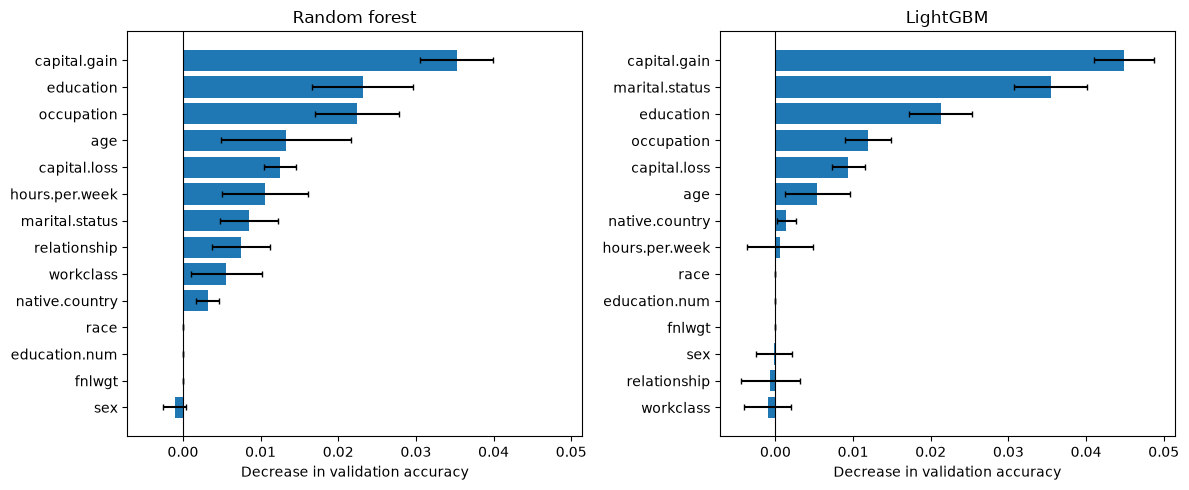

In [15]:
# Use a reproducible validation subset to keep repeated scoring manageable.
X_inspect = X_adult_valid.sample(n=min(1500, len(X_adult_valid)), random_state=123)
y_inspect = y_adult_valid.loc[X_inspect.index]
permutation_results = {}
for name in ["Random forest", "LightGBM"]:
    permutation_results[name] = permutation_importance(
        adult_models[name], X_inspect, y_inspect,
        scoring="accuracy", n_repeats=10, random_state=123, n_jobs=1,
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, (name, result) in zip(axes, permutation_results.items()):
    order = result.importances_mean.argsort()
    ax.barh(X_inspect.columns[order], result.importances_mean[order],
            xerr=result.importances_std[order], capsize=2)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Decrease in validation accuracy")
plt.tight_layout()
plt.show()

**Discuss:** Do the forest's impurity and permutation rankings agree? Why might two related features each have a small permutation importance?

Impurity importance describes training splits and can favour high-cardinality features. Permutation importance depends on the model, evaluation sample, and metric. Its error bars show variation across shuffles, not all sources of uncertainty. Small negative values can occur by chance.

Dropped columns receive zero permutation importance because the pipeline ignores them. Correlated features may substitute for one another, and shuffling may create unrealistic combinations. Evaluate a refitted pipeline before removing features.

## 6. Explain individual predictions with SHAP

SHAP allocates the difference between a reference model output and an individual output among features:

$$f(x) = \text{base value} + \sum_j \phi_j(x).$$

A contribution can be positive for one row and negative for another. We explain the already fitted LightGBM model using 100 fitting rows as background and 300 validation rows for inspection.

`feature_perturbation="interventional"` uses background values to represent unavailable features. It can break dependencies and create unrealistic encoded combinations. Its name does not imply a causal explanation.

In [16]:
lgbm_pipe = adult_models["LightGBM"]
lgbm_preprocessor = lgbm_pipe.named_steps["columntransformer"]
lgbm_model = lgbm_pipe.named_steps["lgbmclassifier"]
lgbm_names = lgbm_preprocessor.get_feature_names_out()

def encode_for_lgbm(frame):
    return pd.DataFrame(lgbm_preprocessor.transform(frame),
                        columns=lgbm_names, index=frame.index)

background = encode_for_lgbm(X_adult_fit.sample(n=100, random_state=123))
X_explain_raw = X_adult_valid.sample(n=300, random_state=123)
X_explain = encode_for_lgbm(X_explain_raw)
explainer = shap.TreeExplainer(
    lgbm_model, data=background,
    feature_perturbation="interventional", model_output="raw",
)
shap_values = explainer(X_explain)
shap_values.shape

(300, 84)

### Check the explained output and units

For this binary LightGBM model, `model_output="raw"` explains **log-odds of class 1**. The base value is the mean raw output over the chosen background sample, not the proportion of positive labels.

We check that base plus contributions reconstructs the raw score, and then convert the **total** to probability using the logistic function. Individual contributions cannot be converted separately into additive probability changes.

In [17]:
raw_scores = lgbm_model.predict(X_explain, raw_score=True)
reconstructed_scores = shap_values.base_values + shap_values.values.sum(axis=1)
np.testing.assert_allclose(reconstructed_scores, raw_scores, atol=1e-5)
np.testing.assert_allclose(
    shap_values.base_values, lgbm_model.predict(background, raw_score=True).mean(),
    atol=1e-5,
)
np.testing.assert_allclose(
    1 / (1 + np.exp(-raw_scores)),
    lgbm_pipe.predict_proba(X_explain_raw)[:, 1],
)
pd.DataFrame({
    "Base + contributions": reconstructed_scores,
    "Model raw score": raw_scores,
    "Probability of >50K": lgbm_pipe.predict_proba(X_explain_raw)[:, 1],
}, index=X_explain_raw.index).head()

,Base + contributions,Model raw score,Probability of >50K
15099,-4.318873,-4.318873,0.013140
14468,1.960487,1.960487,0.876586
29983,-7.779282,-7.779282,0.000418
28587,-5.918548,-5.918548,0.002682
32139,-3.078843,-3.078843,0.043988


### Read two waterfall plots

Select the lowest- and highest-probability examples in the validation sample. These deliberately contrasting cases help us read the plots; they are not typical examples or proof of correct predictions.

In [18]:
probabilities = lgbm_pipe.predict_proba(X_explain_raw)[:, 1]
low_position = int(np.argmin(probabilities))
high_position = int(np.argmax(probabilities))
positions = [low_position, high_position]
example_summary = X_explain_raw.iloc[positions][
    ["age", "education", "occupation", "capital.gain", "hours.per.week"]
].copy()
example_summary["Observed class (1 = >50K)"] = y_adult_valid.loc[example_summary.index]
example_summary["Predicted probability of >50K"] = probabilities[positions]
example_summary

,age,education,occupation,capital.gain,hours.per.week,Observed class (1 = >50K),Predicted probability of >50K
22755,17,11th,Adm-clerical,0,16,0,0.000339
1671,38,Masters,Exec-managerial,99999,70,1,0.999016


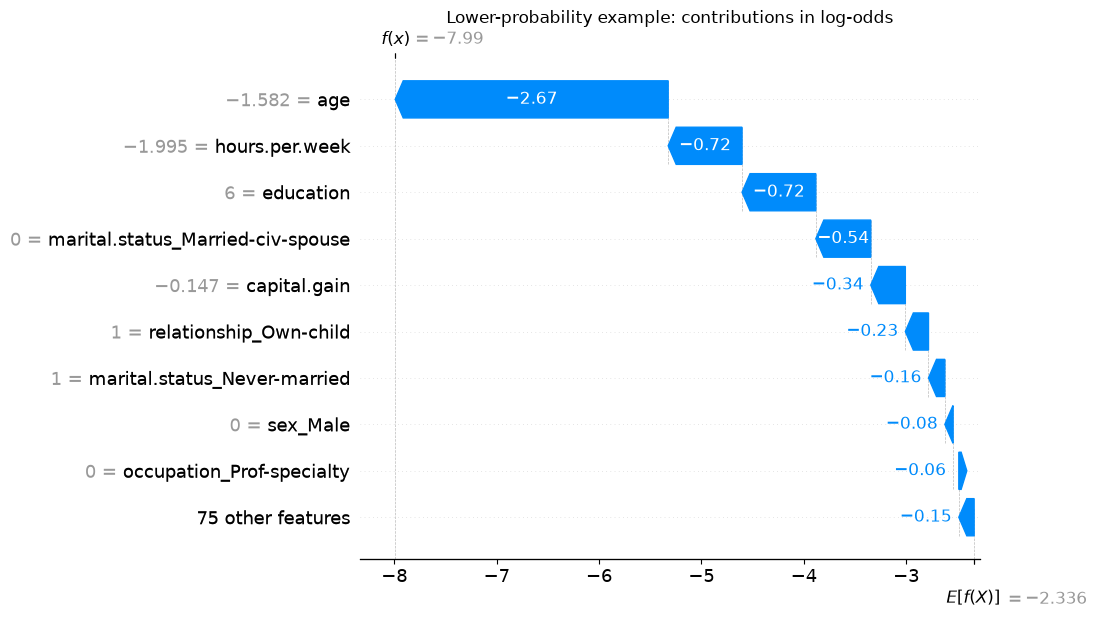

In [19]:
shap.plots.waterfall(shap_values[low_position], max_display=10, show=False)
plt.title("Lower-probability example: contributions in log-odds")
plt.show()

Read the horizontal axis first: contributions are in log-odds. Red arrows raise the output from the base; blue arrows lower it. The final value is the raw score checked above.

**Discuss:** Which inputs contribute most to this prediction? Compare the transformed values on the plot with the original record in the table. A standardized age is not an age in years, and an absent one-hot category can still receive a contribution.

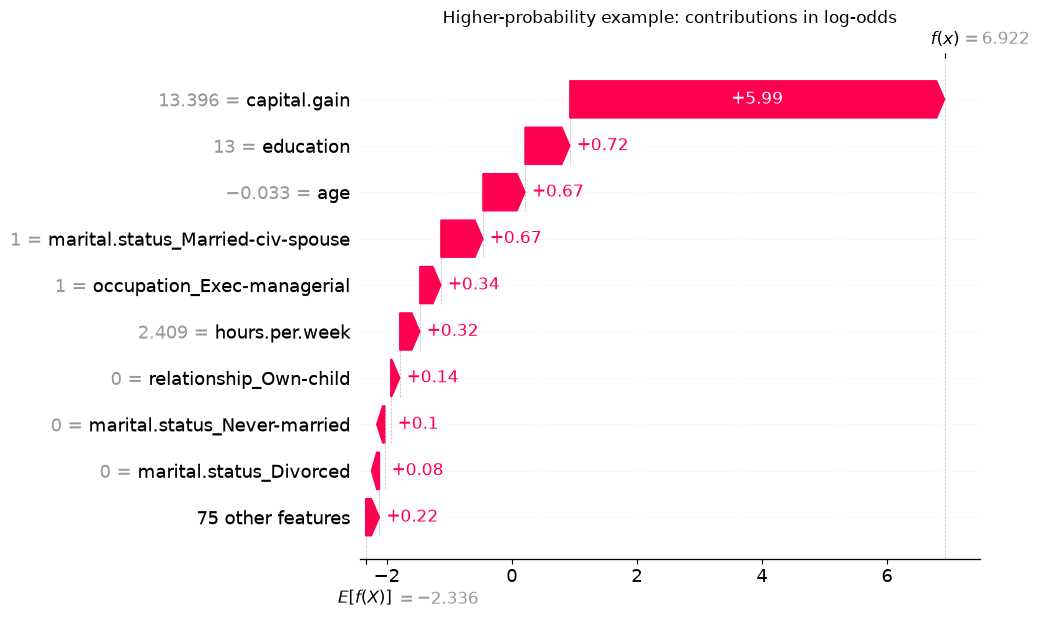

In [20]:
shap.plots.waterfall(shap_values[high_position], max_display=10, show=False)
plt.title("Higher-probability example: contributions in log-odds")
plt.show()

Both plots use the same reference. Compare their largest contributions and signs. A large contribution describes this model output relative to that reference; it is not a recommendation to change the feature.

### Summarize local explanations

Mean **absolute** SHAP contributions summarize magnitude across the explained rows. Positive and negative contributions do not cancel. These bars use log-odds units, not decreases in accuracy.

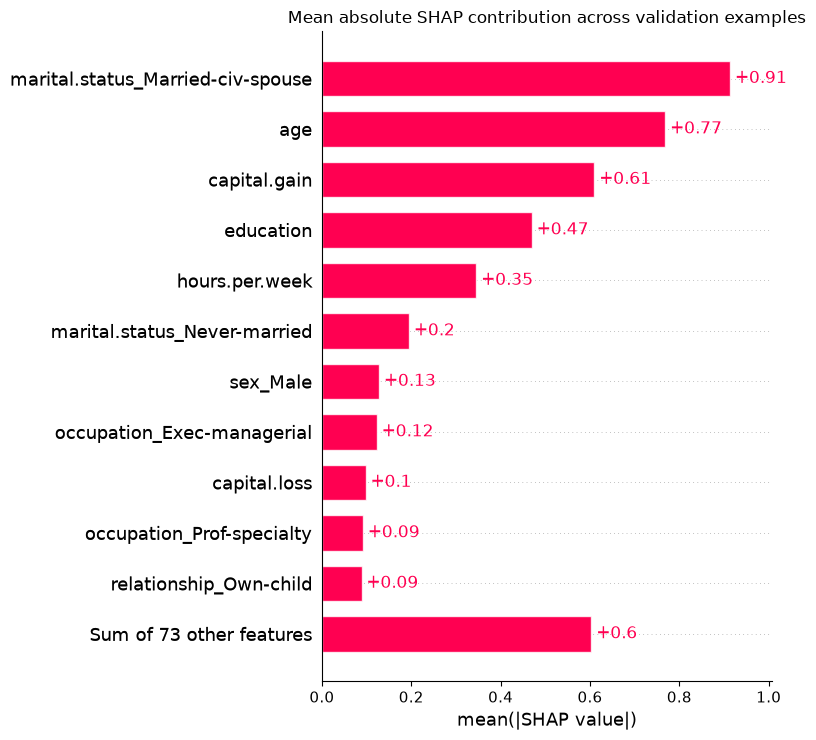

In [21]:
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Mean absolute SHAP contribution across validation examples")
plt.tight_layout()
plt.show()

A beeswarm retains the signed contributions. Each dot is one example; horizontal position is its SHAP contribution and colour is its transformed feature value. For an indicator, high means the category is present.

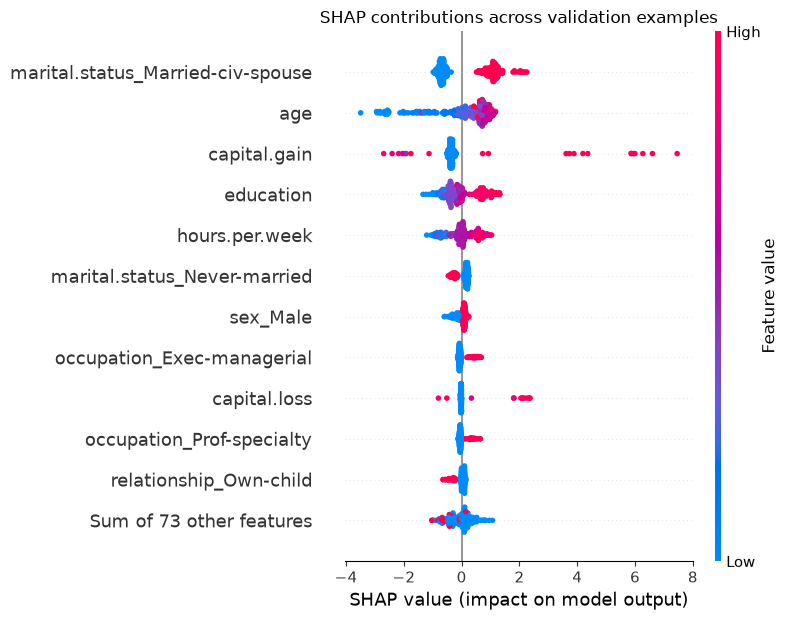

In [22]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP contributions across validation examples")
plt.tight_layout()
plt.show()

**Discuss:** Find a feature whose high values tend to push the output upward. Find one with contributions on both sides. What can these plots tell us that a global importance ranking cannot?

The sample, background, and representation affect these summaries. The grouped final row combines small contributions; it is not another input feature.

### Optional: inspect one feature

The horizontal axis is standardized age; the vertical axis is its SHAP contribution. Variation at similar ages can reflect interactions. This plot does not estimate the effect of becoming older.

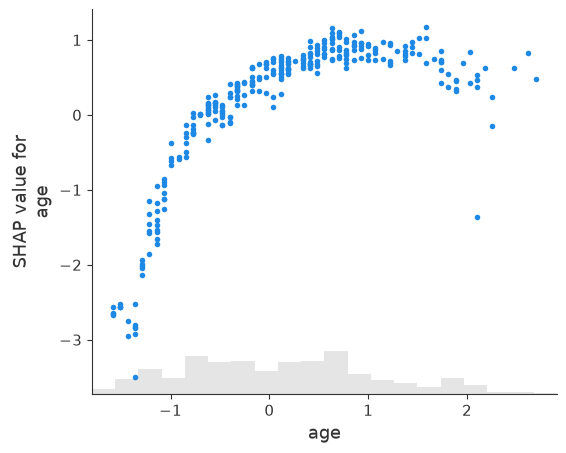

In [23]:
shap.plots.scatter(shap_values[:, "age"])

## 7. Check your interpretation

1. Two correlated measurements each have near-zero permutation importance. Is it safe to remove both?
2. A SHAP base value is −1.0 and contributions are +0.8, +0.5, and −0.3. What are the raw score and probability?
3. Does a large positive coefficient or SHAP value establish a causal effect?

<details>
<summary>Discuss after making your predictions</summary>

1. No. The inputs may substitute for each other. Compare refitted pipelines using validation data or cross-validation before removing them.
2. The raw score is 0 and its probability is 0.5. A contribution of +0.8 is not an 80-percentage-point probability increase.
3. No. These explain a fitted model under a particular representation and reference.

</details>

Use explanations to investigate leakage, unavailable measurements, and surprising predictions. Re-evaluate any revised pipeline and keep test data for the final assessment. Interpretation does not replace validation or a fairness assessment.